<a href="https://colab.research.google.com/github/SantiMB23/El-detective-de-senales-smb/blob/main/Detective_de_Senales.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto: "El Detective de Señales" – Clasificación Automática de Modulaciones
### Fase 1: Generación y Preparación de Datos

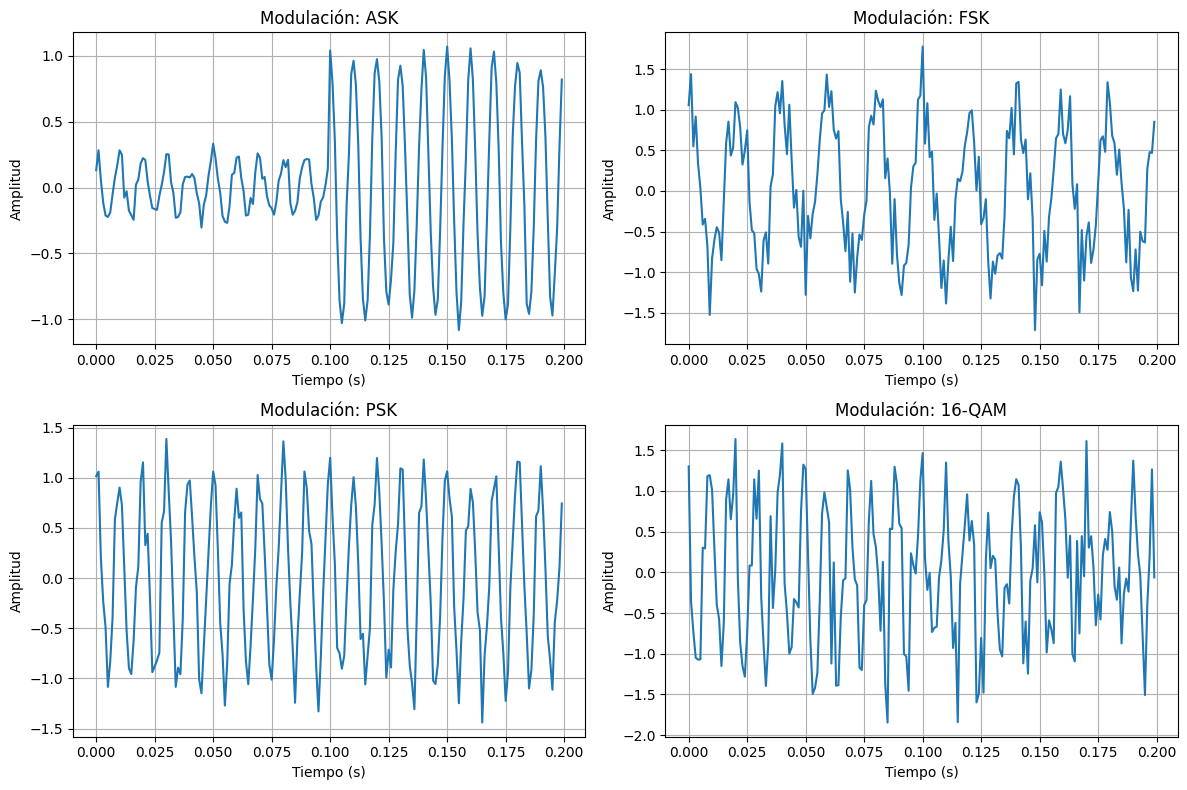

In [ ]:
#Martinez Barreto Santiago
#Fundamentos de Telecomunicaciones G:5402
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

np.random.seed(42)

fs = 1000.0
fc = 100.0
Rs = 10.0
duration = 0.5
t = np.linspace(0, duration, int(fs * duration), endpoint=False)
num_samples_per_symbol = int(fs / Rs)
num_symbols = int(duration * Rs)

def generate_ask(t, bits, fc, fs):
    signal = np.zeros_like(t)
    samples_per_bit = len(t) // len(bits)
    for i, bit in enumerate(bits):
        amplitude = 1.0 if bit == 1 else 0.2
        start = i * samples_per_bit
        end = (i + 1) * samples_per_bit
        signal[start:end] = amplitude * np.cos(2 * np.pi * fc * t[start:end])
    return signal

def generate_fsk(t, bits, fc, fs):
    signal = np.zeros_like(t)
    samples_per_bit = len(t) // len(bits)
    f0 = fc * 0.5
    f1 = fc * 1.5
    for i, bit in enumerate(bits):
        freq = f1 if bit == 1 else f0
        start = i * samples_per_bit
        end = (i + 1) * samples_per_bit
        signal[start:end] = np.cos(2 * np.pi * freq * t[start:end])
    return signal

def generate_psk(t, bits, fc, fs):
    signal = np.zeros_like(t)
    samples_per_bit = len(t) // len(bits)
    for i, bit in enumerate(bits):
        phase = 0 if bit == 1 else np.pi
        start = i * samples_per_bit
        end = (i + 1) * samples_per_bit
        signal[start:end] = np.cos(2 * np.pi * fc * t[start:end] + phase)
    return signal

def generate_16qam(t, num_symbols, fc, fs):
    levels = np.array([-3, -1, 1, 3])
    samples_per_symbol = len(t) // num_symbols

    i_amplitudes = np.random.choice(levels, num_symbols)
    q_amplitudes = np.random.choice(levels, num_symbols)

    signal = np.zeros_like(t)
    for idx in range(num_symbols):
        start = idx * samples_per_symbol
        end = (idx + 1) * samples_per_symbol
        t_seg = t[start:end]
        signal[start:end] = (i_amplitudes[idx] * np.cos(2 * np.pi * fc * t_seg) -
                             q_amplitudes[idx] * np.sin(2 * np.pi * fc * t_seg))
    signal = signal / np.max(np.abs(signal))
    return signal

def add_awgn(signal, snr_db):
    signal_power = np.mean(signal ** 2)
    snr_linear = 10 ** (snr_db / 10.0)
    noise_power = signal_power / snr_linear
    noise = np.random.normal(0, np.sqrt(noise_power), len(signal))
    return signal + noise

samples_per_class = 1000
modulations = ['ASK', 'FSK', 'PSK', '16-QAM']

X_data = []
y_labels = []

for label_idx, mod in enumerate(modulations):
    for _ in range(samples_per_class):
        bits = np.random.randint(0, 2, num_symbols)

        if mod == 'ASK':
            sig = generate_ask(t, bits, fc, fs)
        elif mod == 'FSK':
            sig = generate_fsk(t, bits, fc, fs)
        elif mod == 'PSK':
            sig = generate_psk(t, bits, fc, fs)
        elif mod == '16-QAM':
            sig = generate_16qam(t, num_symbols, fc, fs)

        snr_random = np.random.uniform(0, 20)
        sig_noisy = add_awgn(sig, snr_random)

        X_data.append(sig_noisy)
        y_labels.append(label_idx)

X_data = np.array(X_data)
y_labels = np.array(y_labels)

X_train, X_test, y_train, y_test = train_test_split(
    X_data, y_labels, test_size=0.20, random_state=42, stratify=y_labels
)

plt.figure(figsize=(12, 8))
for i, mod in enumerate(modulations):
    plt.subplot(2, 2, i + 1)
    idx = i * samples_per_class
    plt.plot(t[:200], X_data[idx][:200])
    plt.title(f"Modulación: {mod}")
    plt.xlabel("Tiempo (s)")
    plt.ylabel("Amplitud")
    plt.grid(True)

plt.tight_layout()
plt.show()

### Fase 2: Diseño y Entrenamiento del Modelo

**2.1. Investigación de Arquitecturas (1D-CNN en Formas de Onda)**

Las Redes Neuronales Convolucionales unidimensionales (**1D-CNN**) son ideales para analizar señales moduladas (series de tiempo) por cuatro razones principales:

* **Detección de patrones locales:** Sus filtros recorren la onda y extraen automáticamente los cambios de amplitud (ASK), frecuencia (FSK) o fase (PSK/QAM) sin necesidad de cálculos matemáticos manuales.
* **Invarianza temporal:** Reconocen el tipo de modulación sin importar en qué milisegundo exacto ocurra cada bit.
* **Filtrado de ruido (AWGN):** Las capas convolucionales y de agrupación (*MaxPooling*) conservan la forma principal de la señal e ignoran el ruido blanco aleatorio.
* **Menor costo computacional:** Al compartir pesos a lo largo de la señal, requieren muchos menos parámetros que una red tradicional, evitando el sobreajuste y entrenando más rápido.

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 500, 32)        │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 250, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 250, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 125, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8000)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       512,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 522,820 (1.99 MB)

 Trainable params: 522,820 (1.99 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 9s 46ms/step - accuracy: 0.9072 - loss: 0.2680 - val_accuracy: 0.9925 - val_loss: 0.0487
Epoch 2/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step - accuracy: 0.9847 - loss: 0.0582 - val_accuracy: 0.9925 - val_loss: 0.0314
Epoch 3/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 7s 53ms/step - accuracy: 0.9919 - loss: 0.0280 - val_accuracy: 0.9912 - val_loss: 0.0291
Epoch 4/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 9s 41ms/step - accuracy: 0.9872 - loss: 0.0493 - val_accuracy: 0.9887 - val_loss: 0.0543
Epoch 5/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 5s 50ms/step - accuracy: 0.9928 - loss: 0.0178 - val_accuracy: 0.9937 - val_loss: 0.0298
Epoch 6/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 5s 47ms/step - accuracy: 0.9941 - loss: 0.0131 - val_accuracy: 0.9937 - val_loss: 0.0152
Epoch 7/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - accuracy: 0.9937 - loss: 0.0253 - val_accuracy: 0.9937 - val_loss: 0.0182
Epoch 8/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 5s 41ms/step - accuracy: 0.9947 - loss: 0.0127 - val_accu

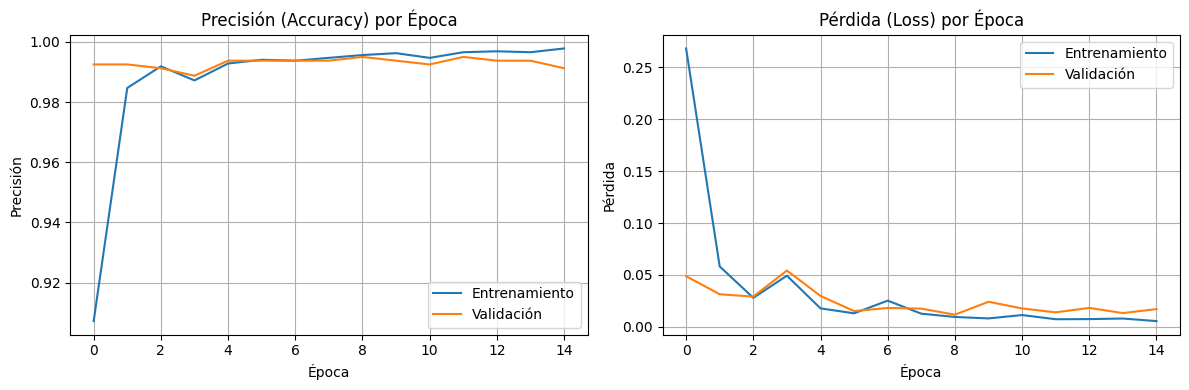

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

X_train_cnn = X_train[..., np.newaxis]
X_test_cnn = X_test[..., np.newaxis]

model = models.Sequential([
    layers.Input(shape=(X_train_cnn.shape[1], 1)),
    layers.Conv1D(filters=32, kernel_size=5, activation='relu', padding='same'),
    layers.MaxPooling1D(pool_size=2),
    layers.Conv1D(filters=64, kernel_size=5, activation='relu', padding='same'),
    layers.MaxPooling1D(pool_size=2),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(4, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

history = model.fit(
    X_train_cnn, y_train,
    epochs=15,
    batch_size=32,
    validation_data=(X_test_cnn, y_test)
)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Entrenamiento')
plt.plot(history.history['val_accuracy'], label='Validación')
plt.title('Precisión (Accuracy) por Época')
plt.xlabel('Época')
plt.ylabel('Precisión')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Entrenamiento')
plt.plot(history.history['val_loss'], label='Validación')
plt.title('Pérdida (Loss) por Época')
plt.xlabel('Época')
plt.ylabel('Pérdida')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

model.save('modelo_modulaciones_fase2.keras')

### Fase 3: Análisis de Evaluación y Robustez

* **3.1. ¿Confunde la IA la modulación ASK con PSK? ¿Por qué sucede?**
  En condiciones de ruido moderado a bajo (0 a 20 dB) la confusión es casi nula, pero cuando el ruido aumenta (SNR negativo), la red tiende a confundir **ASK con PSK** y **16-QAM** porque el ruido blanco aditivo (AWGN) altera directamente la envolvente (amplitud) de la señal. Cuando el ruido añade picos de voltaje sobre los símbolos 0 de ASK (cuya amplitud base es 0.2), su forma de onda pasa a tener una amplitud casi constante similar a la portadora continua de PSK.

* **3.3. ¿En qué punto el modelo se vuelve "ciego" al ruido?**
  De acuerdo con la gráfica de rendimiento (SNR vs. Precisión), el modelo mantiene una precisión superior al 95% desde 0 dB hasta 20 dB. Al bajar a -5 dB comienza a degradarse y alrededor de **-10 dB a -15 dB** la precisión cae cerca del **25%**, punto en el cual la potencia del ruido supera por más de 10 a 30 veces a la potencia de la señal y la red neuronal queda completamente "ciega" (clasificando al azar).

* **3.4. Análisis de errores: ¿Cuál modulación fue la más difícil de clasificar y por qué?**
  La modulación más difícil de clasificar bajo ruido intenso es **16-QAM** (seguida por **ASK**). Esto ocurre porque **16-QAM** codifica información simultáneamente en 16 combinaciones distintas de amplitud y fase; la distancia mínima entre los puntos de su constelación es mucho menor que en BPSK o FSK, por lo que pequeñas variaciones de ruido AWGN desplazan las muestras hacia regiones vecinas y provocan errores de decisión en los filtros convolucionales.

25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step


<Figure size 700x600 with 0 Axes>

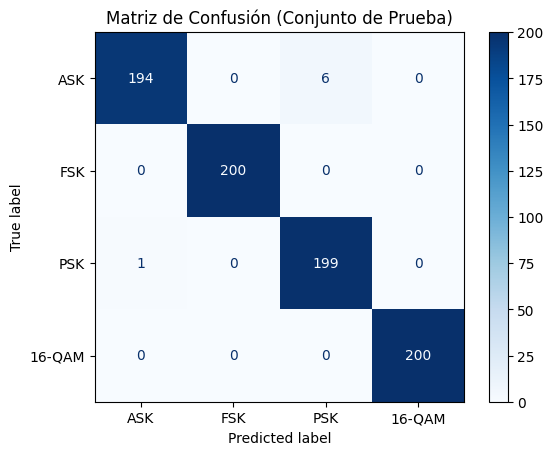

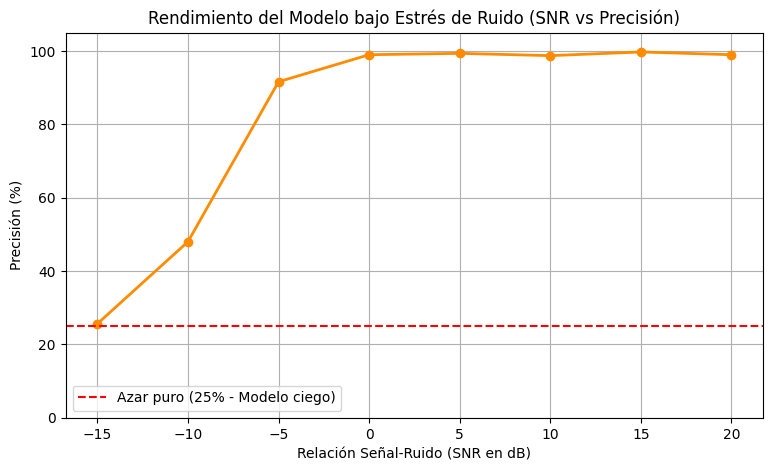

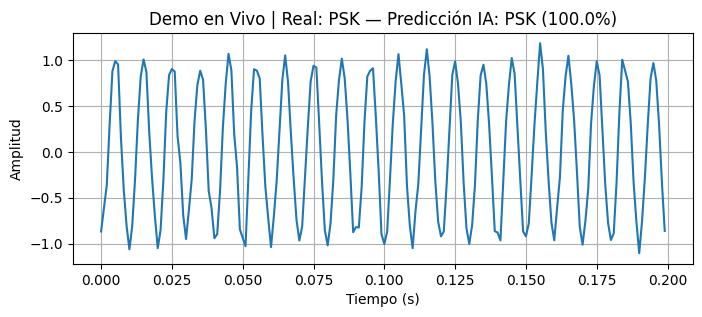

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_pred_probs = model.predict(X_test_cnn)
y_pred = np.argmax(y_pred_probs, axis=1)

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=modulations)

plt.figure(figsize=(7, 6))
disp.plot(cmap='Blues', values_format='d')
plt.title('Matriz de Confusión (Conjunto de Prueba)')
plt.grid(False)
plt.show()

snr_levels = np.arange(-15, 25, 5)
accuracies_by_snr = []
samples_per_snr = 200

for snr in snr_levels:
    X_stress = []
    y_stress = []
    for label_idx, mod in enumerate(modulations):
        for _ in range(samples_per_snr):
            bits = np.random.randint(0, 2, num_symbols)
            if mod == 'ASK':
                sig = generate_ask(t, bits, fc, fs)
            elif mod == 'FSK':
                sig = generate_fsk(t, bits, fc, fs)
            elif mod == 'PSK':
                sig = generate_psk(t, bits, fc, fs)
            elif mod == '16-QAM':
                sig = generate_16qam(t, num_symbols, fc, fs)

            sig_noisy = add_awgn(sig, snr)
            X_stress.append(sig_noisy)
            y_stress.append(label_idx)

    X_stress = np.array(X_stress)[..., np.newaxis]
    y_stress = np.array(y_stress)
    _, acc = model.evaluate(X_stress, y_stress, verbose=0)
    accuracies_by_snr.append(acc * 100)

plt.figure(figsize=(9, 5))
plt.plot(snr_levels, accuracies_by_snr, marker='o', linewidth=2, color='darkorange')
plt.axhline(25, color='red', linestyle='--', label='Azar puro (25% - Modelo ciego)')
plt.title('Rendimiento del Modelo bajo Estrés de Ruido (SNR vs Precisión)')
plt.xlabel('Relación Señal-Ruido (SNR en dB)')
plt.ylabel('Precisión (%)')
plt.xticks(snr_levels)
plt.ylim(0, 105)
plt.grid(True)
plt.legend()
plt.show()

idx_random = np.random.randint(0, len(X_test))
sample_signal = X_test_cnn[idx_random:idx_random+1]
true_mod = modulations[y_test[idx_random]]
pred_probs = model.predict(sample_signal, verbose=0)[0]
pred_mod = modulations[np.argmax(pred_probs)]

plt.figure(figsize=(8, 3))
plt.plot(t[:200], X_test[idx_random][:200])
plt.title(f'Demo en Vivo | Real: {true_mod} — Predicción IA: {pred_mod} ({np.max(pred_probs)*100:.1f}%)')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud')
plt.grid(True)
plt.show()